In [1]:
!pip -q install rdkit openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 28.3 MB/s eta 0:00:00


In [2]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded:
    print("-", filename)

Saving Borton_Corrected_Audit_with_CID100438_review.xlsx to Borton_Corrected_Audit_with_CID100438_review.xlsx
Saving CLAP_CAS_to_SMILES_PubChem_verified.xlsx to CLAP_CAS_to_SMILES_PubChem_verified.xlsx
Uploaded files:
- Borton_Corrected_Audit_with_CID100438_review.xlsx
- CLAP_CAS_to_SMILES_PubChem_verified.xlsx


In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

uploaded_names = list(uploaded.keys())

def load_table(filename, sheet_name=0):
    path = Path(filename)
    if path.suffix.lower() in [".xlsx", ".xls"]:
        return pd.read_excel(path, sheet_name=sheet_name)
    elif path.suffix.lower() == ".csv":
        return pd.read_csv(path)
    else:
        raise ValueError(f"Unsupported file: {filename}")

print("Available files:")
for i, name in enumerate(uploaded_names):
    print(i, name)

# Change these indices if the upload order differs.
BORTON_FILE = uploaded_names[0]
CLAP_FILE = uploaded_names[1]

borton = load_table(BORTON_FILE)
clap = load_table(CLAP_FILE)

print("\nBorton shape:", borton.shape)
print("Borton columns:", borton.columns.tolist())

print("\nCLAP shape:", clap.shape)
print("CLAP columns:", clap.columns.tolist())

Available files:
0 Borton_Corrected_Audit_with_CID100438_review.xlsx
1 CLAP_CAS_to_SMILES_PubChem_verified.xlsx

Borton shape: (1289, 60)
Borton columns: ['original_row', 'id', 'reported_cas', 'reported_chemical_name', 'molecular_formula', 'smiles', 'tier_1_clusters', 'tier_2_clusters', 'cas_normalized', 'cas_format_valid', 'smiles_valid', 'canonical_smiles', 'smiles_status', 'structure_key', 'molecular_weight', 'exact_molecular_weight', 'clogp', 'tpsa', 'hbd', 'hba', 'rotatable_bonds', 'heavy_atoms', 'ring_count', 'CAS_original', 'CAS_normalized', 'CAS_checksum_valid', 'CAS_review_status', 'SMILES_original', 'CID_suggested', 'SMILES_suggested', 'CAS_suggested', 'PubChem_status', 'SMILES_suggested_valid', 'SMILES_correction_status', 'CAS_correction_status', 'CAS_original_preserved', 'CAS_list', 'CAS_count_in_cell', 'CAS_missing', 'CAS_checksum_valid_any', 'CAS_checksum_invalid_all', 'Original_SMILES_valid', 'Original_SMILES_canonical', 'Suggested_SMILES_valid', 'Suggested_SMILES_canoni

In [6]:
# Set these to the exact column names in your files.
BORTON_SMILES_COL = "smiles"
CLAP_SMILES_COL = "SMILES"

# Optional identifiers and names.
BORTON_ID_COL = "id" if "id" in borton.columns else None
BORTON_NAME_COL = "reported_chemical_name" if "reported_chemical_name" in borton.columns else None
BORTON_CAS_COL = "reported_cas" if "reported_cas" in borton.columns else None

CLAP_ID_COL = "Code" if "Code" in clap.columns else None
CLAP_NAME_COL = "Trivial Name" if "Trivial Name" in clap.columns else None

# Add or change this to the actual analytical-method column.
CLAP_METHOD_COL = "Method" if "Method" in clap.columns else None

assert BORTON_SMILES_COL in borton.columns, f"Set the correct Borton SMILES column. Available: {borton.columns.tolist()}"
assert CLAP_SMILES_COL in clap.columns, f"Set the correct CLAP SMILES column. Available: {clap.columns.tolist()}"

In [7]:
from rdkit import Chem, rdBase
from rdkit.Chem.MolStandardize import rdMolStandardize

uncharger = rdMolStandardize.Uncharger()

def standardize_smiles(smiles):
    if pd.isna(smiles) or not str(smiles).strip():
        return None, None, "Missing SMILES"

    mol = Chem.MolFromSmiles(str(smiles))

    if mol is None:
        return None, None, "Invalid SMILES"

    try:
        # Keep original parsed structure separate from standardized structure.
        standardized = rdMolStandardize.Cleanup(mol)
        standardized = rdMolStandardize.FragmentParent(standardized)
        standardized = uncharger.uncharge(standardized)

        canonical = Chem.MolToSmiles(
            standardized,
            canonical=True,
            isomericSmiles=True
        )

        return canonical, standardized, "Valid"

    except Exception as e:
        return None, None, f"Standardization error: {e}"

def prepare_dataset(df, smiles_col, prefix):
    out = df.copy()

    parsed = [
        standardize_smiles(s)
        for s in out[smiles_col]
    ]

    out[f"{prefix}_Canonical_SMILES"] = [x[0] for x in parsed]
    out[f"{prefix}_Status"] = [x[2] for x in parsed]

    mols = [x[1] for x in parsed]
    return out, mols

borton, borton_mols = prepare_dataset(
    borton, BORTON_SMILES_COL, "Borton"
)

clap, clap_mols = prepare_dataset(
    clap, CLAP_SMILES_COL, "CLAP"
)

print("RDKit version:", rdBase.rdkitVersion)
print("\nBorton statuses:")
print(borton["Borton_Status"].value_counts(dropna=False))

print("\nCLAP statuses:")
print(clap["CLAP_Status"].value_counts(dropna=False))

Streaming output truncated to the last 5000 lines.
[10:02:30] Running Normalizer
[10:02:30] Initializing MetalDisconnector
[10:02:30] Running MetalDisconnector
[10:02:30] Initializing Normalizer
[10:02:30] Running Normalizer
[10:02:30] Running LargestFragmentChooser
[10:02:30] Running Uncharger
[10:02:30] Initializing MetalDisconnector
[10:02:30] Running MetalDisconnector
[10:02:30] Initializing Normalizer
[10:02:30] Running Normalizer
[10:02:30] Initializing MetalDisconnector
[10:02:30] Running MetalDisconnector
[10:02:30] Initializing Normalizer
[10:02:30] Running Normalizer
[10:02:30] Running LargestFragmentChooser
[10:02:30] Running Uncharger
[10:02:30] Initializing MetalDisconnector
[10:02:30] Running MetalDisconnector
[10:02:30] Initializing Normalizer
[10:02:30] Running Normalizer
[10:02:30] Initializing MetalDisconnector
[10:02:30] Running MetalDisconnector
[10:02:30] Initializing Normalizer
[10:02:30] Running Normalizer
[10:02:30] Running LargestFragmentChooser
[10:02:30] Runn

RDKit version: 2026.09.1

Borton statuses:
Borton_Status
Valid             1287
Invalid SMILES       2
Name: count, dtype: int64

CLAP statuses:
CLAP_Status
Valid    74
Name: count, dtype: int64


[10:02:32] Running LargestFragmentChooser
[10:02:32] Running Uncharger
[10:02:32] Initializing MetalDisconnector
[10:02:32] Running MetalDisconnector
[10:02:32] Initializing Normalizer
[10:02:32] Running Normalizer
[10:02:32] Initializing MetalDisconnector
[10:02:32] Running MetalDisconnector
[10:02:32] Initializing Normalizer
[10:02:32] Running Normalizer
[10:02:32] Running LargestFragmentChooser
[10:02:32] Running Uncharger
[10:02:32] Initializing MetalDisconnector
[10:02:32] Running MetalDisconnector
[10:02:32] Initializing Normalizer
[10:02:32] Running Normalizer
[10:02:32] Initializing MetalDisconnector
[10:02:32] Running MetalDisconnector
[10:02:32] Initializing Normalizer
[10:02:32] Running Normalizer
[10:02:32] Running LargestFragmentChooser
[10:02:32] Running Uncharger
[10:02:32] Initializing MetalDisconnector
[10:02:32] Running MetalDisconnector
[10:02:32] Initializing Normalizer
[10:02:32] Running Normalizer
[10:02:32] Initializing MetalDisconnector
[10:02:32] Running MetalD

In [10]:
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator, DataStructs

RADIUS = 2
N_BITS = 2048

SIMILARITY_THRESHOLDS = [0.50, 0.70, 0.80, 0.90]

fp_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=RADIUS,
    fpSize=N_BITS
)

def make_fp(mol):
    if mol is None:
        return None
    try:
        # Ensure ring information is initialized
        Chem.FastFindRings(mol)
        return fp_generator.GetFingerprint(mol)
    except Exception:
        return None

borton_fps = [make_fp(m) for m in borton_mols]
clap_fps = [make_fp(m) for m in clap_mols]

valid_clap_indices = [
    i for i, fp in enumerate(clap_fps)
    if fp is not None
]

valid_clap_fps = [clap_fps[i] for i in valid_clap_indices]

print("Valid Borton fingerprints:", sum(fp is not None for fp in borton_fps))
print("Valid CLAP fingerprints:", len(valid_clap_fps))

Valid Borton fingerprints: 1287
Valid CLAP fingerprints: 74


In [11]:
def get_value(row, col):
    if col is None:
        return None
    return row.get(col, None)

def label_for_index(df, idx, id_col, name_col):
    row = df.iloc[idx]
    return {
        "ID": get_value(row, id_col),
        "Name": get_value(row, name_col),
        "Row_Index": idx
    }

results = []
match_details = []

for bi, b_row in borton.iterrows():
    b_mol = borton_mols[bi]
    b_fp = borton_fps[bi]
    b_smiles = b_row.get("Borton_Canonical_SMILES")

    record = {
        "Borton_Row_Index": bi,
        "Borton_ID": get_value(b_row, BORTON_ID_COL),
        "Borton_Name": get_value(b_row, BORTON_NAME_COL),
        "Borton_CAS": get_value(b_row, BORTON_CAS_COL),
        "Borton_Original_SMILES": b_row.get(BORTON_SMILES_COL),
        "Borton_Canonical_SMILES": b_smiles,
        "Borton_Status": b_row.get("Borton_Status"),
        "Exact_Standardized_Match": False,
        "Best_Tanimoto": np.nan,
        "Best_CLAP_Row_Index": None,
        "Best_CLAP_ID": None,
        "Best_CLAP_Name": None,
        "Best_CLAP_Method": None,
        "CLAP_Matches_Above_0.50": 0,
        "CLAP_Matches_Above_0.70": 0,
        "CLAP_Matches_Above_0.80": 0,
        "CLAP_Matches_Above_0.90": 0,
        "Coverage_Status": None
    }

    if b_mol is None or b_fp is None:
        record["Coverage_Status"] = "Unable to compare: invalid/missing Borton SMILES"
        results.append(record)
        continue

    # Exact match after the defined standardization procedure.
    exact_indices = [
        ci for ci in valid_clap_indices
        if clap.iloc[ci]["CLAP_Canonical_SMILES"] == b_smiles
    ]
    record["Exact_Standardized_Match"] = len(exact_indices) > 0

    similarities = DataStructs.BulkTanimotoSimilarity(
        b_fp, valid_clap_fps
    )

    ranked = sorted(
        zip(valid_clap_indices, similarities),
        key=lambda x: x[1],
        reverse=True
    )

    if ranked:
        best_ci, best_score = ranked[0]
        c_row = clap.iloc[best_ci]

        record["Best_Tanimoto"] = float(best_score)
        record["Best_CLAP_Row_Index"] = best_ci
        record["Best_CLAP_ID"] = get_value(c_row, CLAP_ID_COL)
        record["Best_CLAP_Name"] = get_value(c_row, CLAP_NAME_COL)
        record["Best_CLAP_Method"] = get_value(c_row, CLAP_METHOD_COL)

    for threshold in SIMILARITY_THRESHOLDS:
        count = sum(score >= threshold for _, score in ranked)
        record[f"CLAP_Matches_Above_{threshold:.2f}"] = count

    if record["Exact_Standardized_Match"]:
        record["Coverage_Status"] = "Exact standardized structure match"
    elif record["Best_Tanimoto"] >= 0.70:
        record["Coverage_Status"] = "High-similarity candidate; review"
    elif record["Best_Tanimoto"] >= 0.50:
        record["Coverage_Status"] = "Moderate-similarity candidate; review"
    else:
        record["Coverage_Status"] = "No close fingerprint match found"

    results.append(record)

    # Save ranked CLAP matches, including all candidates above 0.50.
    for ci, score in ranked:
        if score < 0.50:
            break

        c_row = clap.iloc[ci]

        match_details.append({
            "Borton_Row_Index": bi,
            "Borton_ID": get_value(b_row, BORTON_ID_COL),
            "Borton_Name": get_value(b_row, BORTON_NAME_COL),
            "Borton_CAS": get_value(b_row, BORTON_CAS_COL),
            "CLAP_Row_Index": ci,
            "CLAP_ID": get_value(c_row, CLAP_ID_COL),
            "CLAP_Name": get_value(c_row, CLAP_NAME_COL),
            "CLAP_Method": get_value(c_row, CLAP_METHOD_COL),
            "CLAP_Original_SMILES": c_row.get(CLAP_SMILES_COL),
            "CLAP_Canonical_SMILES": c_row.get("CLAP_Canonical_SMILES"),
            "Tanimoto_Similarity": float(score),
            "Exact_Standardized_Match": c_row.get("CLAP_Canonical_SMILES") == b_smiles
        })

results_df = pd.DataFrame(results)
matches_df = pd.DataFrame(match_details)

display(results_df.head())
display(matches_df.head())

print("\nCoverage status counts:")
print(results_df["Coverage_Status"].value_counts(dropna=False))

,Borton_Row_Index,Borton_ID,Borton_Name,Borton_CAS,Borton_Original_SMILES,Borton_Canonical_SMILES,Borton_Status,Exact_Standardized_Match,Best_Tanimoto,Best_CLAP_Row_Index,Best_CLAP_ID,Best_CLAP_Name,Best_CLAP_Method,CLAP_Matches_Above_0.50,CLAP_Matches_Above_0.70,CLAP_Matches_Above_0.80,CLAP_Matches_Above_0.90,Coverage_Status
0,0,1,N-Butyldiethanolamine,102-79-4,CCCCN(CCO)CCO,CCCCN(CCO)CCO,Valid,False,0.413793,29.0,RM47,Lauramide DEA,None,0,0,0,0,No close fingerprint match found
1,1,2,N-Lauryldiethanolamine,1541-67-9,OCCN(CCO)CCCCCCCCCCCC,CCCCCCCCCCCCN(CCO)CCO,Valid,False,0.482759,29.0,RM47,Lauramide DEA,None,0,0,0,0,No close fingerprint match found
2,2,3,"2,2-(Tridecylazanediyl)diethanol",18312-57-7,OCCN(CCO)CCCCCCCCCCCCC,CCCCCCCCCCCCCN(CCO)CCO,Valid,False,0.482759,29.0,RM47,Lauramide DEA,None,0,0,0,0,No close fingerprint match found
3,3,4,Triisopropanolamine,122-20-3,CC(CN(CC(O)C)CC(O)C)O,CC(O)CN(CC(C)O)CC(C)O,Valid,False,0.187500,10.0,RM22,Diisooctyl azelate,None,0,0,0,0,No close fingerprint match found
4,4,5,Diethanolamine,111-42-2,OCCNCCO,OCCNCCO,Valid,False,0.181818,56.0,RM106,Ethyl carbitol,None,0,0,0,0,No close fingerprint match found


,Borton_Row_Index,Borton_ID,Borton_Name,Borton_CAS,CLAP_Row_Index,CLAP_ID,CLAP_Name,CLAP_Method,CLAP_Original_SMILES,CLAP_Canonical_SMILES,Tanimoto_Similarity,Exact_Standardized_Match
0,5,6,"1,2,3, propanetriol diacetate",25395-31-7,37,RM64,Triacetin,None,CC(=O)OCC(COC(C)=O)OC(C)=O,CC(=O)OCC(COC(C)=O)OC(C)=O,0.782609,False
1,19,20,"Glycerol Monostearate; 2,3-Dihydroxypropyl oct...",123-94-4; 31566-31-1,30,RM48,Monostearin,None,CCCCCCCCCCCCCCCCCC(=O)OCC(O)CO,CCCCCCCCCCCCCCCCCC(=O)OCC(O)CO,1.000000,True
2,19,20,"Glycerol Monostearate; 2,3-Dihydroxypropyl oct...",123-94-4; 31566-31-1,9,RM17,Butyl stearate,None,CCCCCCCCCCCCCCCCCC(=O)OCCCC,CCCCCCCCCCCCCCCCCC(=O)OCCCC,0.562500,False
3,19,20,"Glycerol Monostearate; 2,3-Dihydroxypropyl oct...",123-94-4; 31566-31-1,73,RM24,Heptylnonyl Adipate,None,CCCCCCCCOC(=O)CCCCC(=O)OCCCCCCCC,CCCCCCCCOC(=O)CCCCC(=O)OCCCCCCCC,0.562500,False
4,19,20,"Glycerol Monostearate; 2,3-Dihydroxypropyl oct...",123-94-4; 31566-31-1,72,RM23,Dibutyl sebacate,None,CCCCOC(=O)CCCCCCCCC(=O)OCCCC,CCCCOC(=O)CCCCCCCCC(=O)OCCCC,0.531250,False



Coverage status counts:
Coverage_Status
No close fingerprint match found                    971
Moderate-similarity candidate; review               163
High-similarity candidate; review                   103
Exact standardized structure match                   50
Unable to compare: invalid/missing Borton SMILES      2
Name: count, dtype: int64


In [12]:
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors

def descriptor_dict(mol):
    if mol is None:
        return {}

    return {
        "MolWt": Descriptors.MolWt(mol),
        "ExactMolWt": Descriptors.ExactMolWt(mol),
        "LogP": Crippen.MolLogP(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "RotatableBonds": Lipinski.NumRotatableBonds(mol),
        "HeavyAtomCount": Lipinski.HeavyAtomCount(mol),
        "RingCount": rdMolDescriptors.CalcNumRings(mol),
        "FractionCSP3": rdMolDescriptors.CalcFractionCSP3(mol)
    }

b_desc = pd.DataFrame([descriptor_dict(m) for m in borton_mols])
c_desc = pd.DataFrame([descriptor_dict(m) for m in clap_mols])

# Prefix to avoid ambiguous column names.
b_desc = b_desc.add_prefix("Borton_")
c_desc = c_desc.add_prefix("CLAP_")

descriptor_output = []

for _, match in matches_df.iterrows():
    bi = int(match["Borton_Row_Index"])
    ci = int(match["CLAP_Row_Index"])

    bd = b_desc.iloc[bi]
    cd = c_desc.iloc[ci]

    item = match.to_dict()

    for desc in [
        "MolWt", "LogP", "TPSA", "HBD", "HBA",
        "RotatableBonds", "HeavyAtomCount",
        "RingCount", "FractionCSP3"
    ]:
        bv = bd.get("Borton_" + desc, np.nan)
        cv = cd.get("CLAP_" + desc, np.nan)

        item["Borton_" + desc] = bv
        item["CLAP_" + desc] = cv

        if pd.notna(bv) and pd.notna(cv):
            item[desc + "_Absolute_Difference"] = abs(float(bv) - float(cv))
        else:
            item[desc + "_Absolute_Difference"] = np.nan

    descriptor_output.append(item)

match_descriptor_df = pd.DataFrame(descriptor_output)
display(match_descriptor_df.head())

,Borton_Row_Index,Borton_ID,Borton_Name,Borton_CAS,CLAP_Row_Index,CLAP_ID,CLAP_Name,CLAP_Method,CLAP_Original_SMILES,CLAP_Canonical_SMILES,...,RotatableBonds_Absolute_Difference,Borton_HeavyAtomCount,CLAP_HeavyAtomCount,HeavyAtomCount_Absolute_Difference,Borton_RingCount,CLAP_RingCount,RingCount_Absolute_Difference,Borton_FractionCSP3,CLAP_FractionCSP3,FractionCSP3_Absolute_Difference
0,5,6,"1,2,3, propanetriol diacetate",25395-31-7,37,RM64,Triacetin,None,CC(=O)OCC(COC(C)=O)OC(C)=O,CC(=O)OCC(COC(C)=O)OC(C)=O,...,1.0,12.0,15.0,3.0,0.0,0.0,0.0,0.714286,0.666667,0.047619
1,19,20,"Glycerol Monostearate; 2,3-Dihydroxypropyl oct...",123-94-4; 31566-31-1,30,RM48,Monostearin,None,CCCCCCCCCCCCCCCCCC(=O)OCC(O)CO,CCCCCCCCCCCCCCCCCC(=O)OCC(O)CO,...,0.0,25.0,25.0,0.0,0.0,0.0,0.0,0.952381,0.952381,0.000000
2,19,20,"Glycerol Monostearate; 2,3-Dihydroxypropyl oct...",123-94-4; 31566-31-1,9,RM17,Butyl stearate,None,CCCCCCCCCCCCCCCCCC(=O)OCCCC,CCCCCCCCCCCCCCCCCC(=O)OCCCC,...,0.0,25.0,24.0,1.0,0.0,0.0,0.0,0.952381,0.954545,0.002165
3,19,20,"Glycerol Monostearate; 2,3-Dihydroxypropyl oct...",123-94-4; 31566-31-1,73,RM24,Heptylnonyl Adipate,None,CCCCCCCCOC(=O)CCCCC(=O)OCCCCCCCC,CCCCCCCCOC(=O)CCCCC(=O)OCCCCCCCC,...,0.0,25.0,26.0,1.0,0.0,0.0,0.0,0.952381,0.909091,0.043290
4,19,20,"Glycerol Monostearate; 2,3-Dihydroxypropyl oct...",123-94-4; 31566-31-1,72,RM23,Dibutyl sebacate,None,CCCCOC(=O)CCCCCCCCC(=O)OCCCC,CCCCOC(=O)CCCCCCCCC(=O)OCCCC,...,4.0,25.0,22.0,3.0,0.0,0.0,0.0,0.952381,0.888889,0.063492


In [13]:
substructure_results = []

for _, row in results_df.iterrows():
    bi = int(row["Borton_Row_Index"])
    ci = row["Best_CLAP_Row_Index"]

    if pd.isna(ci) or borton_mols[bi] is None:
        continue

    ci = int(ci)
    bm = borton_mols[bi]
    cm = clap_mols[ci]

    if cm is None:
        continue

    substructure_results.append({
        "Borton_Row_Index": bi,
        "Best_CLAP_Row_Index": ci,
        "Borton_Contains_CLAP": bm.HasSubstructMatch(cm),
        "CLAP_Contains_Borton": cm.HasSubstructMatch(bm)
    })

substructure_df = pd.DataFrame(substructure_results)
display(substructure_df.head())

,Borton_Row_Index,Best_CLAP_Row_Index,Borton_Contains_CLAP,CLAP_Contains_Borton
0,0,29,False,True
1,1,29,False,True
2,2,29,False,False
3,3,10,False,False
4,4,56,False,False


In [14]:
from google.colab import files

borton_invalid = borton[borton["Borton_Status"] != "Valid"].copy()
clap_invalid = clap[clap["CLAP_Status"] != "Valid"].copy()

summary = pd.DataFrame({
    "Metric": [
        "Borton records",
        "Borton valid structures",
        "Borton invalid/missing structures",
        "CLAP records",
        "CLAP valid structures",
        "CLAP invalid/missing structures",
        "Borton exact standardized matches",
        "Borton high-similarity candidates (>=0.70)",
        "Borton moderate-similarity candidates (0.50-0.69)"
    ],
    "Count": [
        len(borton),
        int((borton["Borton_Status"] == "Valid").sum()),
        len(borton_invalid),
        len(clap),
        int((clap["CLAP_Status"] == "Valid").sum()),
        len(clap_invalid),
        int(results_df["Exact_Standardized_Match"].sum()),
        int((results_df["Best_Tanimoto"] >= 0.70).sum()),
        int(((results_df["Best_Tanimoto"] >= 0.50) &
             (results_df["Best_Tanimoto"] < 0.70)).sum())
    ]
})

output_file = "Borton_FDA_CLAP_Similarity_Coverage.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    summary.to_excel(writer, sheet_name="Summary", index=False)
    results_df.to_excel(writer, sheet_name="Borton_Coverage", index=False)
    matches_df.to_excel(writer, sheet_name="All_Matches_0.50plus", index=False)
    match_descriptor_df.to_excel(writer, sheet_name="Descriptor_Comparison", index=False)
    substructure_df.to_excel(writer, sheet_name="Substructure_Check", index=False)
    borton_invalid.to_excel(writer, sheet_name="Borton_Structure_Review", index=False)
    clap_invalid.to_excel(writer, sheet_name="CLAP_Structure_Review", index=False)

print("Exported:", output_file)
files.download(output_file)

Exported: Borton_FDA_CLAP_Similarity_Coverage.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
!pip -q install pandas openpyxl matplotlib seaborn

In [16]:
from google.colab import files
uploaded = files.upload()

input_file = next(iter(uploaded.keys()))
print("Uploaded:", input_file)

Saving Borton_FDA_CLAP_Similarity_Coverage.xlsx to Borton_FDA_CLAP_Similarity_Coverage (1).xlsx
Uploaded: Borton_FDA_CLAP_Similarity_Coverage (1).xlsx


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

xls = pd.ExcelFile(input_file)
print("Available sheets:", xls.sheet_names)

coverage = pd.read_excel(input_file, sheet_name="Borton_Coverage")
matches = pd.read_excel(input_file, sheet_name="All_Matches_0.50plus")

# Load descriptor results if available
descriptor_df = (
    pd.read_excel(input_file, sheet_name="Descriptor_Comparison")
    if "Descriptor_Comparison" in xls.sheet_names else pd.DataFrame()
)

print("Borton compounds:", len(coverage))
print("Similarity match records:", len(matches))
display(coverage.head())

Available sheets: ['Summary', 'Borton_Coverage', 'All_Matches_0.50plus', 'Descriptor_Comparison', 'Substructure_Check', 'Borton_Structure_Review', 'CLAP_Structure_Review']
Borton compounds: 1289
Similarity match records: 880


,Borton_Row_Index,Borton_ID,Borton_Name,Borton_CAS,Borton_Original_SMILES,Borton_Canonical_SMILES,Borton_Status,Exact_Standardized_Match,Best_Tanimoto,Best_CLAP_Row_Index,Best_CLAP_ID,Best_CLAP_Name,Best_CLAP_Method,CLAP_Matches_Above_0.50,CLAP_Matches_Above_0.70,CLAP_Matches_Above_0.80,CLAP_Matches_Above_0.90,Coverage_Status
0,0,1,N-Butyldiethanolamine,102-79-4,CCCCN(CCO)CCO,CCCCN(CCO)CCO,Valid,False,0.413793,29.0,RM47,Lauramide DEA,NaN,0,0,0,0,No close fingerprint match found
1,1,2,N-Lauryldiethanolamine,1541-67-9,OCCN(CCO)CCCCCCCCCCCC,CCCCCCCCCCCCN(CCO)CCO,Valid,False,0.482759,29.0,RM47,Lauramide DEA,NaN,0,0,0,0,No close fingerprint match found
2,2,3,"2,2-(Tridecylazanediyl)diethanol",18312-57-7,OCCN(CCO)CCCCCCCCCCCCC,CCCCCCCCCCCCCN(CCO)CCO,Valid,False,0.482759,29.0,RM47,Lauramide DEA,NaN,0,0,0,0,No close fingerprint match found
3,3,4,Triisopropanolamine,122-20-3,CC(CN(CC(O)C)CC(O)C)O,CC(O)CN(CC(C)O)CC(C)O,Valid,False,0.187500,10.0,RM22,Diisooctyl azelate,NaN,0,0,0,0,No close fingerprint match found
4,4,5,Diethanolamine,111-42-2,OCCNCCO,OCCNCCO,Valid,False,0.181818,56.0,RM106,Ethyl carbitol,NaN,0,0,0,0,No close fingerprint match found


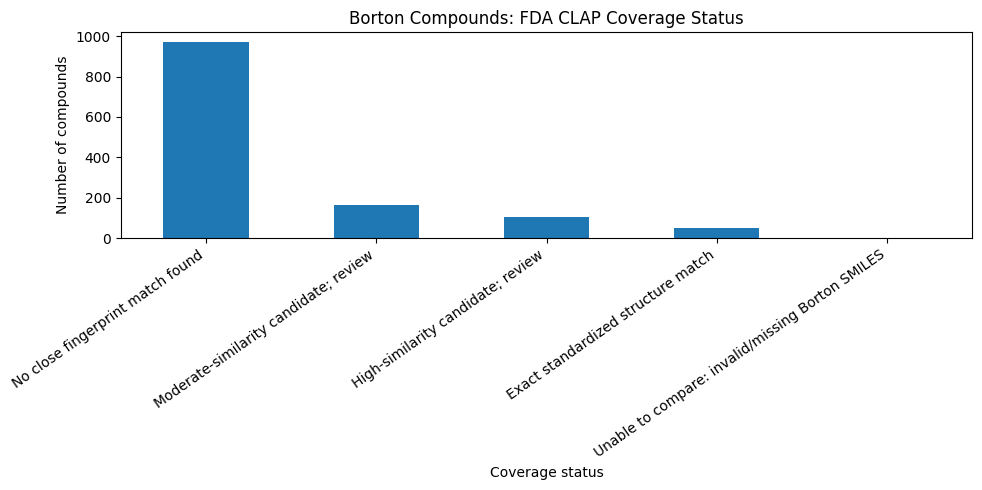

In [18]:
status_col = "Coverage_Status"

status_counts = coverage[status_col].fillna("Unknown").value_counts()

plt.figure(figsize=(10, 5))
status_counts.plot(kind="bar")
plt.title("Borton Compounds: FDA CLAP Coverage Status")
plt.xlabel("Coverage status")
plt.ylabel("Number of compounds")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

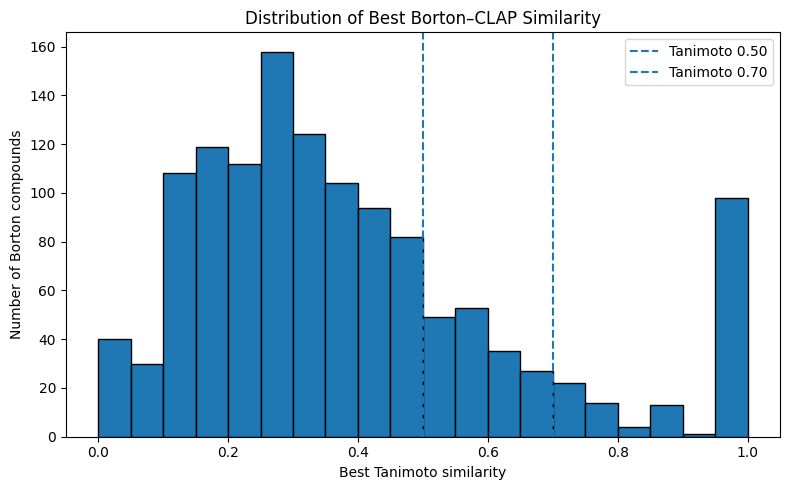

In [19]:
scores = pd.to_numeric(
    coverage["Best_Tanimoto"], errors="coerce"
).dropna()

plt.figure(figsize=(8, 5))
plt.hist(scores, bins=20, edgecolor="black")
plt.axvline(0.50, linestyle="--", label="Tanimoto 0.50")
plt.axvline(0.70, linestyle="--", label="Tanimoto 0.70")
plt.xlabel("Best Tanimoto similarity")
plt.ylabel("Number of Borton compounds")
plt.title("Distribution of Best Borton–CLAP Similarity")
plt.legend()
plt.tight_layout()
plt.show()

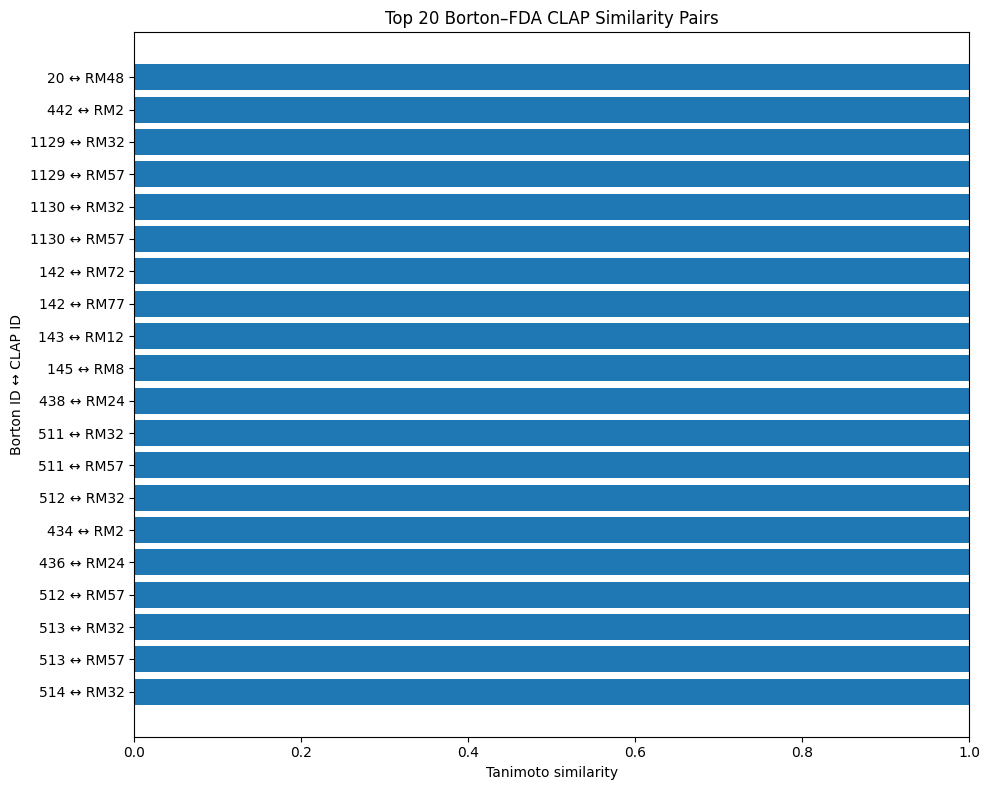

,Borton_Row_Index,Borton_ID,Borton_Name,Borton_CAS,CLAP_Row_Index,CLAP_ID,CLAP_Name,CLAP_Method,CLAP_Original_SMILES,CLAP_Canonical_SMILES,Tanimoto_Similarity,Exact_Standardized_Match,Pair
1,19,20,"Glycerol Monostearate; 2,3-Dihydroxypropyl oct...",123-94-4; 31566-31-1,30,RM48,Monostearin,NaN,CCCCCCCCCCCCCCCCCC(=O)OCC(O)CO,CCCCCCCCCCCCCCCCCC(=O)OCC(O)CO,1.0,True,20 ↔ RM48
392,441,442,"Benzenepropanoic acid, 3,5-bis(1,1-dimethyleth...",125643-61-0,1,RM2,Irganox 1076,NaN,CCCCCCCCCCCCCCCCCCOC(=O)CCc1cc(c(O)c(c1)C(C)(C...,CCCCCCCCCCCCCCCCCCOC(=O)CCc1cc(C(C)(C)C)c(O)c(...,1.0,False,442 ↔ RM2
808,1128,1129,icosanoic acid,506-30-9,18,RM32,Palmitic acid,NaN,CCCCCCCCCCCCCCCC(O)=O,CCCCCCCCCCCCCCCC(=O)O,1.0,False,1129 ↔ RM32
809,1128,1129,icosanoic acid,506-30-9,34,RM57,Stearic acid,NaN,CCCCCCCCCCCCCCCCCC(O)=O,CCCCCCCCCCCCCCCCCC(=O)O,1.0,False,1129 ↔ RM57
812,1129,1130,heptadecanoic acid,506-12-7,18,RM32,Palmitic acid,NaN,CCCCCCCCCCCCCCCC(O)=O,CCCCCCCCCCCCCCCC(=O)O,1.0,False,1130 ↔ RM32
813,1129,1130,heptadecanoic acid,506-12-7,34,RM57,Stearic acid,NaN,CCCCCCCCCCCCCCCCCC(O)=O,CCCCCCCCCCCCCCCCCC(=O)O,1.0,False,1130 ↔ RM57
34,141,142,Di-isononyl phthalate (DINP),28553-12-0,39,RM72,Diisooctyl phthalate,NaN,CC(C)CCCCCOC(=O)c1ccccc1C(=O)OCCCCCC(C)C,CC(C)CCCCCOC(=O)c1ccccc1C(=O)OCCCCCC(C)C,1.0,False,142 ↔ RM72
35,141,142,Di-isononyl phthalate (DINP),28553-12-0,41,RM77,Diisononyl phthalate,NaN,CC(C)CCCCCCOC(=O)c1ccccc1C(=O)OCCCCCCC(C)C,CC(C)CCCCCCOC(=O)c1ccccc1C(=O)OCCCCCCC(C)C,1.0,True,142 ↔ RM77
41,142,143,Tri-2-ethylhexyl trimellitate,3319-31-1,67,RM12,Tris (2-ethylhexyl) trimellitate,NaN,CCCCC(CC)COC(=O)c1ccc(C(=O)OCC(CC)CCCC)c(c1)C(...,CCCCC(CC)COC(=O)c1ccc(C(=O)OCC(CC)CCCC)c(C(=O)...,1.0,True,143 ↔ RM12
47,144,145,Bis-(2-ethylhexyl)phthalate; Di(2-ethylhexyl) ...,117-81-7,4,RM8,Di-(2-ethylhexyl)phthalate,NaN,CCCCC(CC)COC(=O)c1ccccc1C(=O)OCC(CC)CCCC,CCCCC(CC)COC(=O)c1ccccc1C(=O)OCC(CC)CCCC,1.0,True,145 ↔ RM8


In [20]:
if not matches.empty and "Tanimoto_Similarity" in matches.columns:
    top_matches = matches.sort_values(
        "Tanimoto_Similarity", ascending=False
    ).head(20).copy()

    top_matches["Pair"] = (
        top_matches["Borton_ID"].fillna(top_matches["Borton_Row_Index"]).astype(str)
        + " ↔ "
        + top_matches["CLAP_ID"].fillna(top_matches["CLAP_Row_Index"]).astype(str)
    )

    plt.figure(figsize=(10, 8))
    plt.barh(
        top_matches["Pair"].astype(str)[::-1],
        top_matches["Tanimoto_Similarity"][::-1]
    )
    plt.xlabel("Tanimoto similarity")
    plt.ylabel("Borton ID ↔ CLAP ID")
    plt.title("Top 20 Borton–FDA CLAP Similarity Pairs")
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.show()

    display(top_matches)
else:
    print("No similarity-pair records available.")

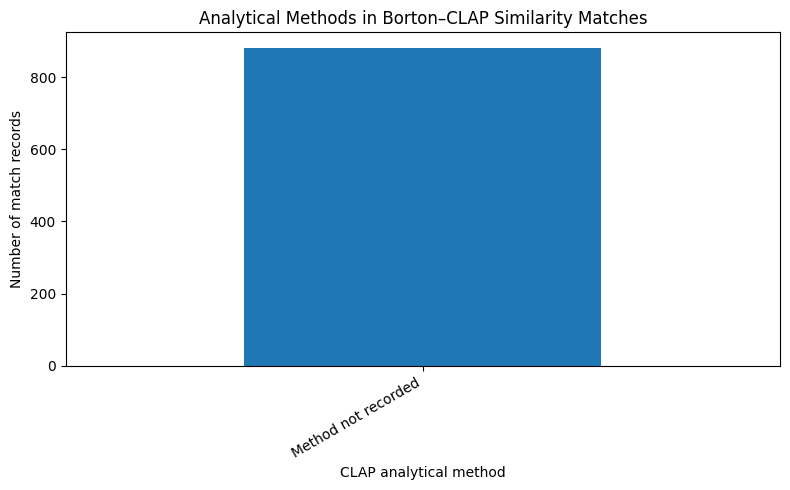

In [21]:
if not matches.empty and "CLAP_Method" in matches.columns:
    method_counts = (
        matches["CLAP_Method"]
        .fillna("Method not recorded")
        .astype(str)
        .value_counts()
    )

    plt.figure(figsize=(8, 5))
    method_counts.plot(kind="bar")
    plt.title("Analytical Methods in Borton–CLAP Similarity Matches")
    plt.xlabel("CLAP analytical method")
    plt.ylabel("Number of match records")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("CLAP_Method column unavailable. Check the method labels in your input data.")

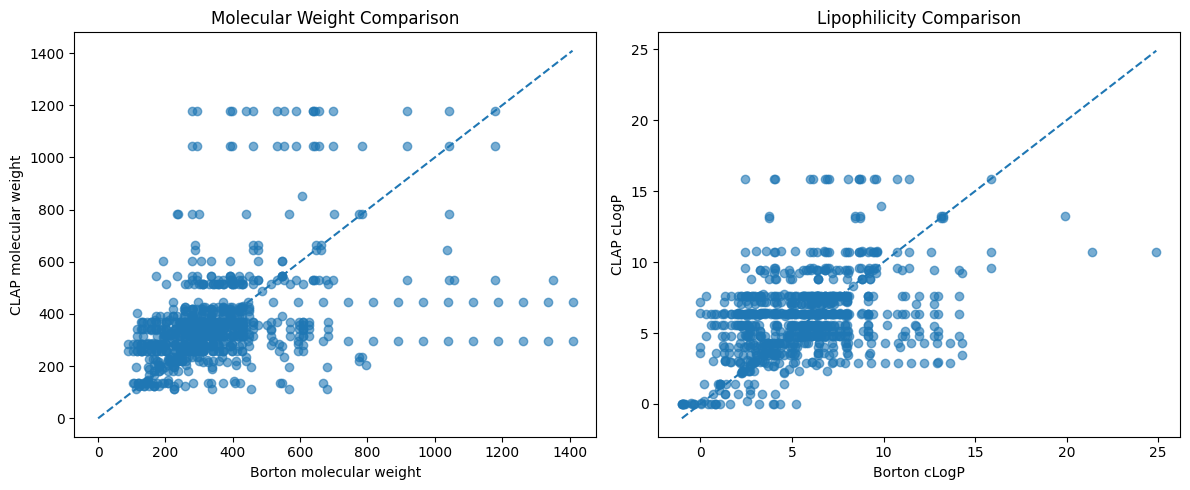

In [22]:
if not descriptor_df.empty:
    required = [
        "Borton_MolWt", "CLAP_MolWt",
        "Borton_LogP", "CLAP_LogP"
    ]

    if all(c in descriptor_df.columns for c in required):
        plot_df = descriptor_df[required].apply(
            pd.to_numeric, errors="coerce"
        ).dropna()

        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        axes[0].scatter(
            plot_df["Borton_MolWt"],
            plot_df["CLAP_MolWt"],
            alpha=0.6
        )
        max_mw = max(
            plot_df["Borton_MolWt"].max(),
            plot_df["CLAP_MolWt"].max()
        )
        axes[0].plot([0, max_mw], [0, max_mw], linestyle="--")
        axes[0].set_xlabel("Borton molecular weight")
        axes[0].set_ylabel("CLAP molecular weight")
        axes[0].set_title("Molecular Weight Comparison")

        axes[1].scatter(
            plot_df["Borton_LogP"],
            plot_df["CLAP_LogP"],
            alpha=0.6
        )
        min_logp = min(
            plot_df["Borton_LogP"].min(),
            plot_df["CLAP_LogP"].min()
        )
        max_logp = max(
            plot_df["Borton_LogP"].max(),
            plot_df["CLAP_LogP"].max()
        )
        axes[1].plot(
            [min_logp, max_logp],
            [min_logp, max_logp],
            linestyle="--"
        )
        axes[1].set_xlabel("Borton cLogP")
        axes[1].set_ylabel("CLAP cLogP")
        axes[1].set_title("Lipophilicity Comparison")

        plt.tight_layout()
        plt.show()
    else:
        print("Expected descriptor columns not found.")
else:
    print("Descriptor comparison sheet is empty or unavailable.")

In [23]:
from pathlib import Path
import matplotlib.pyplot as plt

output_dir = Path("Borton_CLAP_Plots")
output_dir.mkdir(exist_ok=True)

# Re-run each plotting cell with this immediately before plt.show():
# plt.savefig(output_dir / "plot_name.png", dpi=300, bbox_inches="tight")

print("Create and save each figure using plt.savefig() before plt.show().")

Create and save each figure using plt.savefig() before plt.show().
